# LeetCode #59: Spiral Matrix II

https://leetcode.com/problems/spiral-matrix-ii/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute Force: Walk and Turn** | $O(n^2)$ | $O(n^2)$ + a second $O(n^2)$ grid | Walk one square at a time and turn right whenever the next square is off the grid or already visited, keeping a separate "visited" grid to check. |
| **Boundary Simulation** ★ | $O(n^2)$ | $O(n^2)$ for the answer, $O(1)$ besides | Four "walls" mark the edges of the part still empty. Fill along each wall, then move it inward. Four numbers replace the visited grid. |

$n^2$ is the number of squares: at the largest allowed $n = 20$, that's 400. $O(n^2)$ time means each square is written once. The answer *is* an $n \times n$ grid, so no method can use less than $O(n^2)$ memory; the difference is what each one needs on top of it.

---

## Understanding the Methods

The task: write the numbers $1, 2, \dots, n^2$ into an $n \times n$ grid in a clockwise spiral, starting at the top-left corner and winding inward.

### Brute Force: Walk and Turn
Keep a direction (right, down, left, up) and a grid of visited flags. Step forward; if the next square is off the edge or already visited, turn clockwise. It works, but every step pays for a bounds check plus a lookup, and the flags double the memory. (The answer grid's own zeros can stand in for the flags, which already removes the second grid.)

### Optimal: Boundary Simulation ★
Keep four numbers: `top`, `bottom`, `left`, `right`, the first and last row and column that are still empty. One lap is four straight passes: along the top row, down the right column, back along the bottom row, up the left column. After each pass that row or column is full, so its wall moves one step inward straight away. Repeat while the walls haven't crossed.

**Why this is better than the brute force:** the walls already say where every pass starts and stops, so there's no turn test at each square and no visited grid. Moving each wall right after its pass is also what stops a corner from being written twice.

**Constraints:**
* `1 <= n <= 20`

## Explain Like I'm a Newbie

### What the question is actually asking

Write 1, 2, 3, … up to $n^2$ into an $n \times n$ grid, walking clockwise from the top-left corner and spiralling inward.

```
n = 4:    1  2  3  4
         12 13 14  5
         11 16 15  6
         10  9  8  7
```

### The one idea you need: four walls that close in

Keep four walls: `top`, `bottom`, `left` and `right`, the first and last row and column that are still empty. One lap is four straight passes: along the top wall, down the right wall, back along the bottom wall, up the left wall.

As soon as a pass is done, that wall is full, so move it one step inward **right then**, before the next pass. That's what keeps the corners straight. The top pass writes the top-right corner; `top` moves down a row; so the down pass starts one row lower and never touches that corner again.

Each lap peels off one ring. The next lap does exactly the same thing on the smaller square inside, and the laps stop when the walls cross.

### What that means in code

`while top <= bottom and left <= right`, with four `for` loops inside, each followed by moving its own wall. One counter, `num`, keeps counting across every pass. The two `if` checks in front of the bottom and left passes stop a pass from re-walking a row or column that's already full. In a square grid those passes would be empty anyway whenever the checks fail, but the checks are what make the same code correct for a rectangle.

### Mistakes people make the first time

1. **Treating the middle square as a special case.** Fill the rings, then write $n^2$ into `matrix[n//2][n//2]`. Both LeetCode samples, `n = 3` and `n = 1`, are odd, so both pass. At `n = 4` there is no middle square: that line overwrites the 15 at row 2, column 2 with 16, leaving two 16s and no 15. The walls version never asks whether there's a middle. A lap with one square left is just a top pass of length one.
2. **Moving all four walls at the end of the lap** instead of after each pass. The down pass then starts on row 0 and overwrites the corner's 3 with a 4.
3. **Looping on the counter, `while num < n * n`.** It stops one number early, and the last square stays 0.

### Things worth knowing

The grid is the answer, so its $O(n^2)$ memory can't be avoided. The walls add four integers. At the largest `n = 20`, the whole job is 400 writes.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"I keep four walls, `top`, `bottom`, `left`, `right`, marking the part of the grid that's still empty. Each lap fills the top row left to right, the right column downward, the bottom row right to left, and the left column upward, and each wall moves inward the moment its pass is done. One counter runs from 1 to $n^2$. Every square is written once, so it's $O(n^2)$ time, and the only memory beyond the answer is four integers."*

And then, unprompted: *"the guards before the bottom and left passes don't change anything for a square, but they're what would keep this correct for a rectangle."*

---

### I slide the problem across the table

> **You:** "So for `n = 3` it's `[[1,2,3],[8,9,4],[7,6,5]]`: clockwise from the top-left, winding inward. Always square?"

**"Always square, `n` from 1 to 20."** Good. Square versus rectangle is the clarifier that actually changes something here, because it decides whether the last lap can be a single row or column.

> **You:** "And I'm building the grid myself and returning it, so there's no input to preserve?"

**"Right, you allocate it."** That's fine to confirm, though it's less important.

What I don't need is "what if `n` is zero or negative?" The constraints say 1 to 20, and asking makes me think you didn't read them.

---

### Now tell me what's actually hard about it

If you open with "I'll simulate it", I'll ask what's hard about simulating it. What I want to hear:

> **You:** "The corners. Each corner sits at the end of one pass and the start of the next, so if both passes include it, it's written twice and every number after it shifts by one. Every corner has to belong to exactly one pass."

> **You:** "And knowing when to stop. Odd `n` ends on a single middle square, even `n` ends on a two-by-two ring with no middle at all. I'd like one rule that handles both, not a special case for the middle."

That second point is the one most people miss, because both LeetCode samples are odd. Saying it before you've written anything tells me you looked past the samples.

Then the technique falls out of those two problems:

> **You:** "So I keep four walls. A pass runs between two walls, inclusive, and the wall it ran along moves in straight after. The next pass starts inside the new wall, so it can't touch that corner. And I loop while the walls haven't crossed, which handles odd and even the same way."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "An outer `while` for the laps, four `for` loops inside it. Each square is written exactly once, by exactly one pass, so the total is $n^2$ writes: $O(n^2)$. At `n = 20` that's 400. Memory: the grid I'm returning, which is $O(n^2)$ by definition, plus four walls and a counter."

If you mention the walk-and-turn version with a direction array, that's fine. I'll ask what it costs per step, and the answer I want is "a bounds check and a visited check every step, and a second grid unless I reuse the zeros in the answer". Same big-O, more moving parts.

---

### Now whiteboard it

```
matrix = [[0] * n for _ in range(n)]
top, bottom, left, right = 0, n - 1, 0, n - 1
num = 1
while top <= bottom and left <= right:
    for col in range(left, right + 1):
        matrix[top][col] = num; num += 1
    top += 1
```

> **You:** "`right + 1` because the range is inclusive of the wall. And `top` moves straight away: the top-right corner is done, so the down pass has to start a row below it."

That's the line I watch. If `top += 1` isn't there, I'll ask where the down pass starts, and the honest answer is "on the corner I just wrote".

```
    for row in range(top, bottom + 1):
        matrix[row][right] = num; num += 1
    right -= 1
    if top <= bottom:
        for col in range(right, left - 1, -1):
            matrix[bottom][col] = num; num += 1
        bottom -= 1
    if left <= right:
        for row in range(bottom, top - 1, -1):
            matrix[row][left] = num; num += 1
        left += 1
return matrix
```

> **You:** "The two `if`s ask whether there's still a row and a column left after the first two passes. In a square, when they fail, the loops they guard would be empty anyway. In a rectangle that's one row tall, they'd walk back over the row I just filled."

If you can say that, I know the guards aren't cargo-culted from Spiral Matrix I.

---

### Walk me through it before you say you're done

> **You:** "`n = 3`. Lap one: top row gets 1, 2, 3, `top` becomes 1. Right column, rows 1 to 2, gets 4, 5, `right` becomes 1. Bottom row, columns 1 down to 0, gets 6, 7, `bottom` becomes 1. Left column, row 1 only, gets 8, `left` becomes 1. Lap two: all four walls are 1, so the top pass writes 9 into the middle and `top` becomes 2. The down pass is empty, both guards fail, and the loop stops."

Then the clarifier from the start:

> **You:** "`n = 4`: the second lap is a two-by-two ring. 13 and 14 along the top, 15 down, 16 back along the bottom, and the up pass is empty. There's no middle square, and nothing in the code needed to know that."

That's the dry run I want. It ties the odd-versus-even worry back to a loop condition that never mentions either.

---

### Then tell me where it breaks, before I ask

It's optimal: you have to write $n^2$ numbers, and you write each one once. So the honest beat is how it generalises:

> **You:** "For an `m × n` rectangle, the same loop works, and that's when the guards matter. A wide rectangle ends on a single row: the top pass fills it, and without `if top <= bottom` the bottom pass would walk back over it. Reading a matrix in spiral order, Spiral Matrix I, is this exact loop with the assignment turned into an append."

That's a candidate who knows which lines are there for this problem and which are there for its sibling.

---

### What would worry me

- **A special case for the middle square**, tested only on the odd samples.
- **Walls moved at the end of the lap** instead of after each pass, so a corner is written twice.
- **Exclusive ranges on some passes and inclusive on others**, with no story about which pass owns each corner.
- **No dry run on an even `n`**, when both samples are odd.

## Solutions

### C#

In [ ]:
public class Solution {
    public int[][] GenerateMatrix(int n) {
        int[][] matrix = new int[n][];
        for (int i = 0; i < n; i++) matrix[i] = new int[n];

        // The four walls: first/last row and column that are still empty
        int top = 0, bottom = n - 1, left = 0, right = n - 1, num = 1;

        // One lap per ring; stops when the walls cross (odd n: after the middle
        // square, even n: after the last 2x2 ring), so no special case for the middle
        while (top <= bottom && left <= right) {
            // Fill right across the top wall, corners included
            for (int col = left; col <= right; col++) matrix[top][col] = num++;
            // Move the wall in RIGHT AWAY: the top-right corner is done, so the
            // down pass must start one row lower or it writes that corner twice
            top++;
            // Fill down along the right wall
            for (int row = top; row <= bottom; row++) matrix[row][right] = num++;
            right--;
            // Fill left across the bottom wall, if a row is still left
            // (in a square it only fails when this pass would be empty anyway;
            // it matters for a rectangle)
            if (top <= bottom) {
                for (int col = right; col >= left; col--) matrix[bottom][col] = num++;
                bottom--;
            }
            // Fill up along the left wall, if a column is still left
            if (left <= right) {
                for (int row = bottom; row >= top; row--) matrix[row][left] = num++;
                left++;
            }
        }
        return matrix;
    }
}

### Python

In [ ]:
class Solution:
    def generateMatrix(self, n: int) -> list[list[int]]:
        matrix = [[0] * n for _ in range(n)]
        # The four walls: first/last row and column that are still empty
        top, bottom, left, right = 0, n - 1, 0, n - 1
        num = 1

        # One lap per ring; stops when the walls cross (odd n: after the middle
        # square, even n: after the last 2x2 ring), so no special case for the middle
        while top <= bottom and left <= right:
            # Fill right across the top wall, corners included
            for col in range(left, right + 1):
                matrix[top][col] = num; num += 1
            # Move the wall in RIGHT AWAY: the top-right corner is done, so the
            # down pass must start one row lower or it writes that corner twice
            top += 1
            # Fill down along the right wall
            for row in range(top, bottom + 1):
                matrix[row][right] = num; num += 1
            right -= 1
            # Fill left across the bottom wall, if a row is still left
            # (in a square it only fails when this pass would be empty anyway;
            # it matters for a rectangle)
            if top <= bottom:
                for col in range(right, left - 1, -1):
                    matrix[bottom][col] = num; num += 1
                bottom -= 1
            # Fill up along the left wall, if a column is still left
            if left <= right:
                for row in range(bottom, top - 1, -1):
                    matrix[row][left] = num; num += 1
                left += 1
        return matrix

### Go

In [ ]:
func generateMatrix(n int) [][]int {
    matrix := make([][]int, n)
    for i := range matrix {
        matrix[i] = make([]int, n)
    }
    // The four walls: first/last row and column that are still empty
    top, bottom, left, right := 0, n-1, 0, n-1
    num := 1

    // One lap per ring; stops when the walls cross (odd n: after the middle
    // square, even n: after the last 2x2 ring), so no special case for the middle
    for top <= bottom && left <= right {
        // Fill right across the top wall, corners included
        for col := left; col <= right; col++ { matrix[top][col] = num; num++ }
        // Move the wall in RIGHT AWAY: the top-right corner is done, so the
        // down pass must start one row lower or it writes that corner twice
        top++
        // Fill down along the right wall
        for row := top; row <= bottom; row++ { matrix[row][right] = num; num++ }
        right--
        // Fill left across the bottom wall, if a row is still left
        // (in a square it only fails when this pass would be empty anyway;
        // it matters for a rectangle)
        if top <= bottom {
            for col := right; col >= left; col-- { matrix[bottom][col] = num; num++ }
            bottom--
        }
        // Fill up along the left wall, if a column is still left
        if left <= right {
            for row := bottom; row >= top; row-- { matrix[row][left] = num; num++ }
            left++
        }
    }
    return matrix
}

### Rust

The walls are `i32`, not `usize`: on the last lap `right` or `bottom` can step to one below `left` or `top`, and for `n = 1` that's −1, which a `usize` can't hold.

In [ ]:
impl Solution {
    pub fn generate_matrix(n: i32) -> Vec<Vec<i32>> {
        let n = n as usize;
        let mut matrix = vec![vec![0i32; n]; n];
        // The four walls, as i32 so right/bottom can drop to -1 without underflow
        let (mut top, mut bottom) = (0i32, n as i32 - 1);
        let (mut left, mut right) = (0i32, n as i32 - 1);
        let mut num = 1i32;

        // One lap per ring; stops when the walls cross (odd n: after the middle
        // square, even n: after the last 2x2 ring), so no special case for the middle
        while top <= bottom && left <= right {
            // Fill right across the top wall, corners included
            for col in left..=right { matrix[top as usize][col as usize] = num; num += 1; }
            // Move the wall in RIGHT AWAY: the top-right corner is done, so the
            // down pass must start one row lower or it writes that corner twice
            top += 1;
            // Fill down along the right wall
            for row in top..=bottom { matrix[row as usize][right as usize] = num; num += 1; }
            right -= 1;
            // Fill left across the bottom wall, if a row is still left
            // (in a square it only fails when this pass would be empty anyway;
            // it matters for a rectangle)
            if top <= bottom {
                for col in (left..=right).rev() { matrix[bottom as usize][col as usize] = num; num += 1; }
                bottom -= 1;
            }
            // Fill up along the left wall, if a column is still left
            if left <= right {
                for row in (top..=bottom).rev() { matrix[row as usize][left as usize] = num; num += 1; }
                left += 1;
            }
        }
        matrix
    }
}

## Example Scenarios

### 1. Common Case — n = 3
**Input:** `n = 3`

The first lap fills the outer ring with 1 to 8: across the top, down the right, back along the bottom, up the left. All four walls then sit on row and column 1, so the second lap's top pass writes 9 into the middle and the walls cross. **Output:** `[[1,2,3],[8,9,4],[7,6,5]]`

### 2. Slightly Complex — n = 4, No Middle Square
**Input:** `n = 4`

The outer ring takes 1 to 12. The inner ring is two by two: 13 and 14 across its top, 15 down, 16 back along its bottom, and its up pass is empty. There's no middle square, and the loop doesn't need to know that. **Output:** `[[1,2,3,4],[12,13,14,5],[11,16,15,6],[10,9,8,7]]`

### 3. Edge Case: Time Factor — n = 20
**Input:** `n = 20`

The largest grid: 400 squares in 10 laps, each lap one ring smaller than the last. Every square is written exactly once, so the work is $n^2 = 400$ writes, $O(n^2)$. **Output:** a 20 × 20 spiral whose first row is 1 to 20 and whose last number, 400, lands at row 10, column 9.

### 4. Edge Case: Space Factor — n = 1
**Input:** `n = 1`

The answer grid is a single square. The top pass writes 1, `top` becomes 1, and every other pass is empty. Whatever `n` is, the memory beyond the answer is the same four walls and a counter. **Output:** `[[1]]`

### 5. Almost-Impossible but Plausible — n = 2, a Ring with Nothing Inside
**Input:** `n = 2`

One lap: 1 and 2 across the top, 3 down the right, 4 back along the bottom, and the up pass has nothing left to fill. Code that writes $n^2$ into a "middle" square would put a second 4 on top of the 3 at row 1, column 1. **Output:** `[[1,2],[4,3]]`

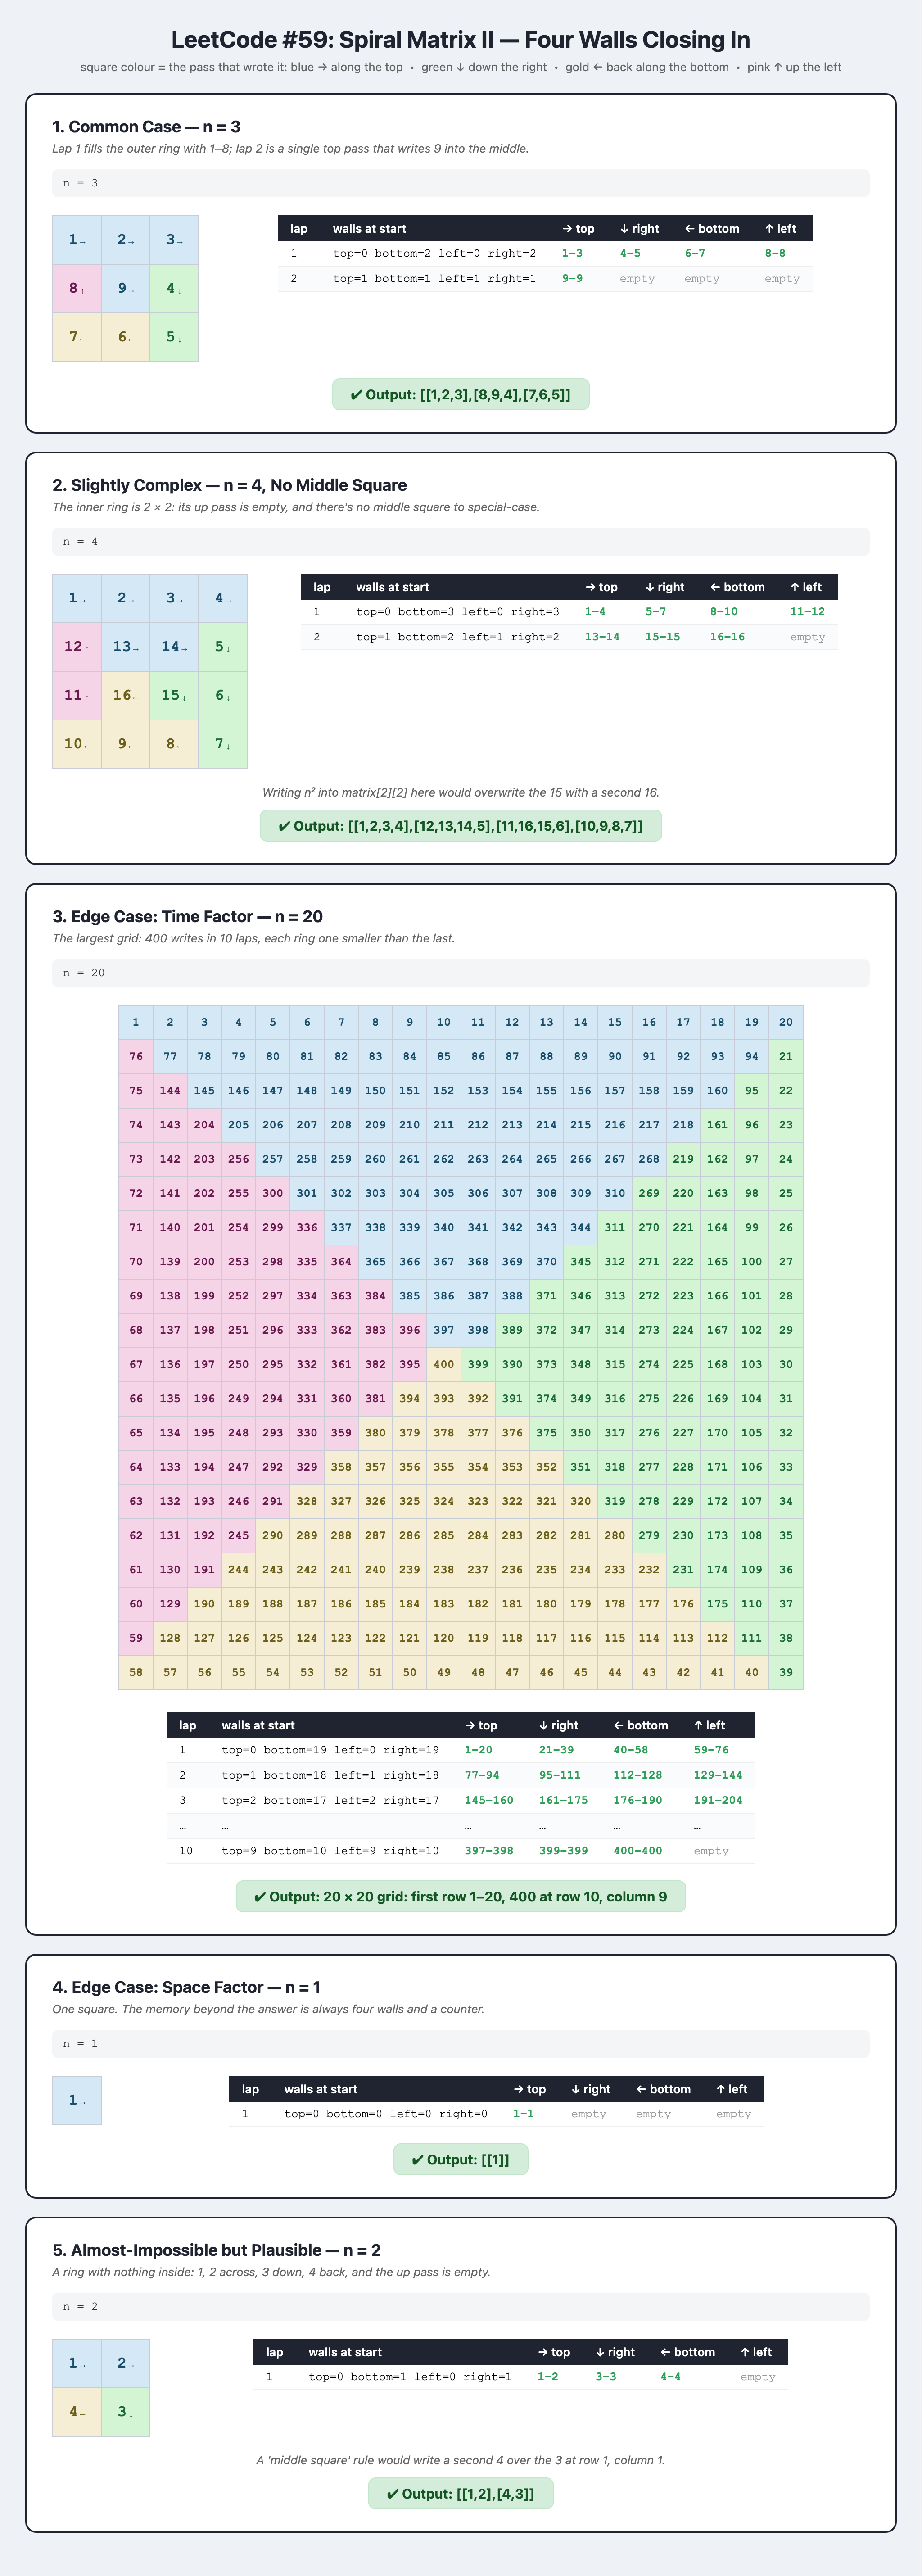

## Watch It Run

*Watch the top wall move down right after the first pass: that's why the down pass starts below the corner instead of writing over the 3.*

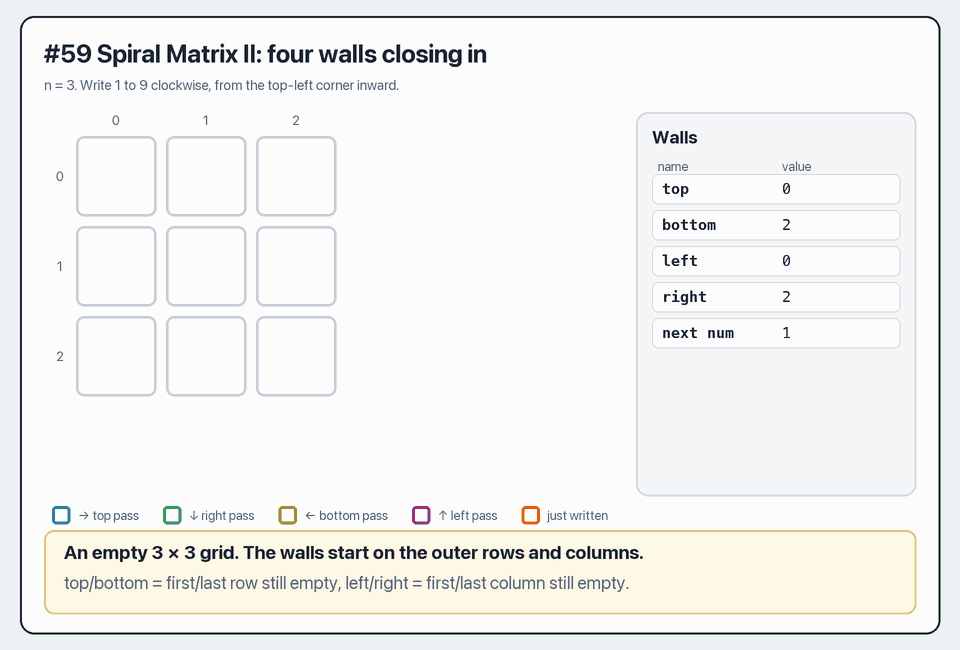

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0059.html)**